In [41]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_cleaned.csv")
df.shape

(8786, 16)

In [42]:
print(df["release_year"].dtype)
print(df["release_year"].min(), df["release_year"].max())

int64
1925 2021


In [43]:
df["release_year"].isnull().sum()

np.int64(0)

In [44]:
df["release_year"].nunique

<bound method IndexOpsMixin.nunique of 0       2020
1       2021
2       2021
3       2021
4       1993
        ... 
8781    2016
8782    2016
8783    2012
8784    2016
8785    2016
Name: release_year, Length: 8786, dtype: int64>

In [45]:
df[df["release_year"] < 1960][["title", "type", "release_year"]].sort_values("release_year").head(5)

,title,type,release_year
421,Pioneers: First Women Filmmakers*,TV Show,1925
5694,Prelude to War,Movie,1942
6033,The Battle of Midway,Movie,1942
6418,Undercover: How to Operate Behind Enemy Lines,Movie,1943
6487,Why We Fight: The Battle of Russia,Movie,1943


In [46]:
yearly = df["release_year"].value_counts().sort_index()
yearly.tail(12)

release_year
2010     192
2011     185
2012     236
2013     286
2014     351
2015     555
2016     901
2017    1030
2018    1144
2019    1029
2020     953
2021     592
Name: count, dtype: int64

In [47]:
print("Peak year:", yearly.idxmax(), "with", yearly.max(), "titles")


Peak year: 2018 with 1144 titles


In [48]:
print("Titles before 2000:", yearly[yearly.index < 2000].sum())
print("Years with fewer than 10 titles:", (yearly < 10).sum())


Titles before 2000: 525
Years with fewer than 10 titles: 31


In [49]:
by_type = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
by_type.tail(8)

type,Movie,TV Show
release_year,,
2014,263,88
2015,396,159
2016,658,243
2017,765,265
2018,766,378
2019,632,397
2020,517,436
2021,277,315


In [50]:
df["date_added"] = pd.to_datetime(df["date_added"])
df["date_added"].max()

Timestamp('2021-09-25 00:00:00')

In [51]:
recent = yearly.loc[2000:]
recent.shape

(22,)

In [52]:
growth = (recent.pct_change() * 100).round(1)
growth.tail(8)

release_year
2014    22.7
2015    58.1
2016    62.3
2017    14.3
2018    11.1
2019   -10.1
2020    -7.4
2021   -37.9
Name: count, dtype: float64

In [53]:
print("Biggest growth:", growth.idxmax(), growth.max(), "%")
print("Biggest drop (excluding 2021):", growth.loc[:2020].idxmin(), growth.loc[:2020].min(), "%")

Biggest growth: 2016 62.3 %
Biggest drop (excluding 2021): 2019 -10.1 %


In [54]:
smooth = recent.rolling(3).mean().round(1)
smooth.tail(8)


release_year
2014     291.0
2015     397.3
2016     602.3
2017     828.7
2018    1025.0
2019    1067.7
2020    1042.0
2021     858.0
Name: count, dtype: float64

In [55]:
decade = (df["release_year"] // 10 * 10).value_counts().sort_index()
decade

release_year
1920       1
1940      15
1950      11
1960      25
1970      70
1980     129
1990     274
2000     807
2010    5909
2020    1545
Name: count, dtype: int64

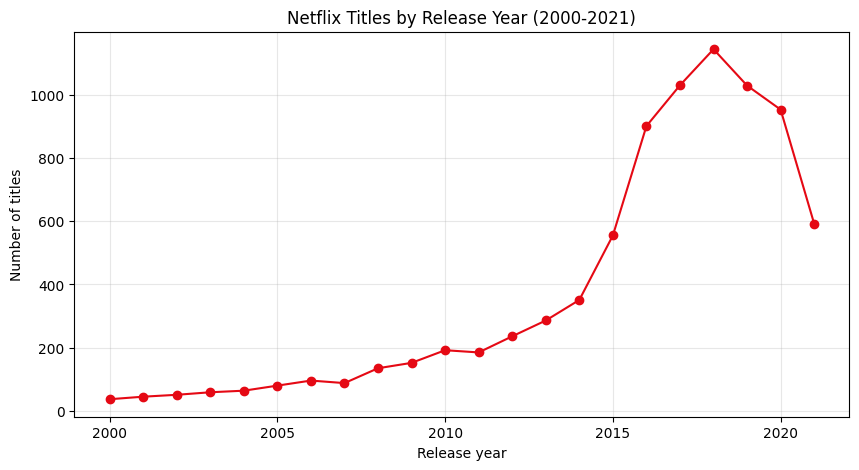

In [56]:
plt.figure(figsize=(10, 5))
plt.plot(recent.index, recent.values, marker="o", color="#E50914")
plt.title("Netflix Titles by Release Year (2000-2021)")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.grid(alpha=0.3)
plt.show()

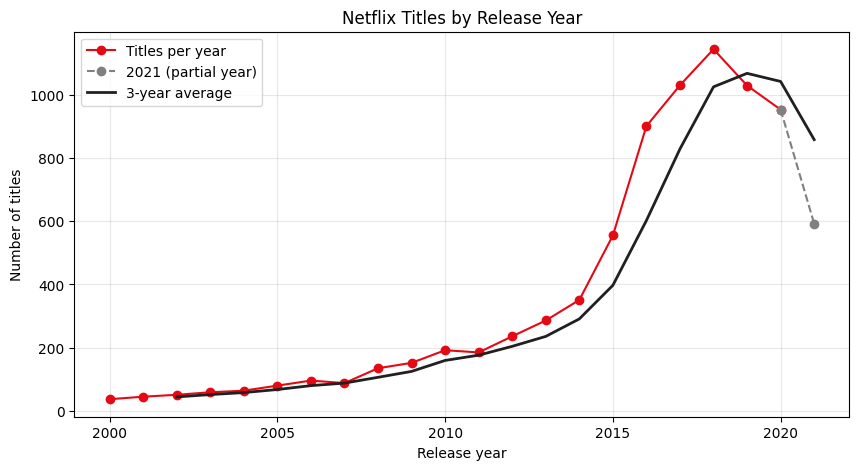

In [57]:
full = recent.loc[:2020]

plt.figure(figsize=(10, 5))
plt.plot(full.index, full.values, marker="o", color="#E50914", label="Titles per year")
plt.plot([2020, 2021], [recent[2020], recent[2021]], linestyle="--", marker="o", color="gray", label="2021 (partial year)")
plt.plot(smooth.index, smooth.values, color="#221F1F", linewidth=2, label="3-year average")
plt.title("Netflix Titles by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("release_trend.png", dpi=150, bbox_inches="tight")
plt.show()

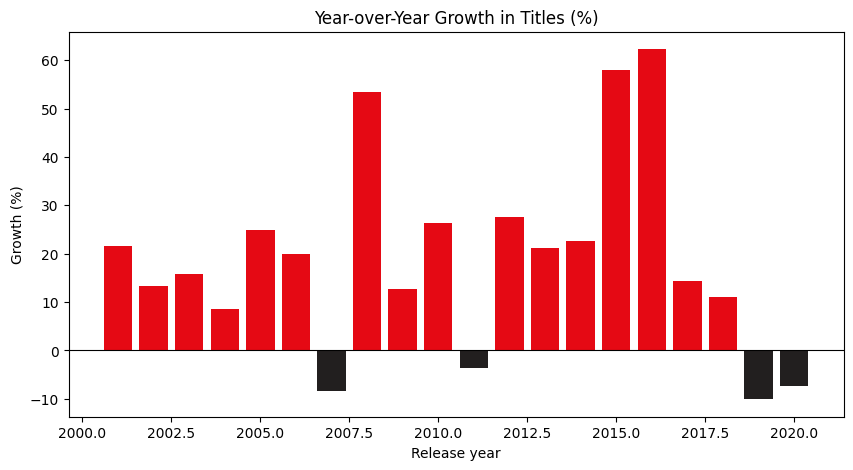

In [58]:
g = growth.loc[2001:2020]
colors = ["#E50914" if v >= 0 else "#221F1F" for v in g]

plt.figure(figsize=(10, 5))
plt.bar(g.index, g.values, color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Year-over-Year Growth in Titles (%)")
plt.xlabel("Release year")
plt.ylabel("Growth (%)")
plt.savefig("release_growth.png", dpi=150, bbox_inches="tight")
plt.show()


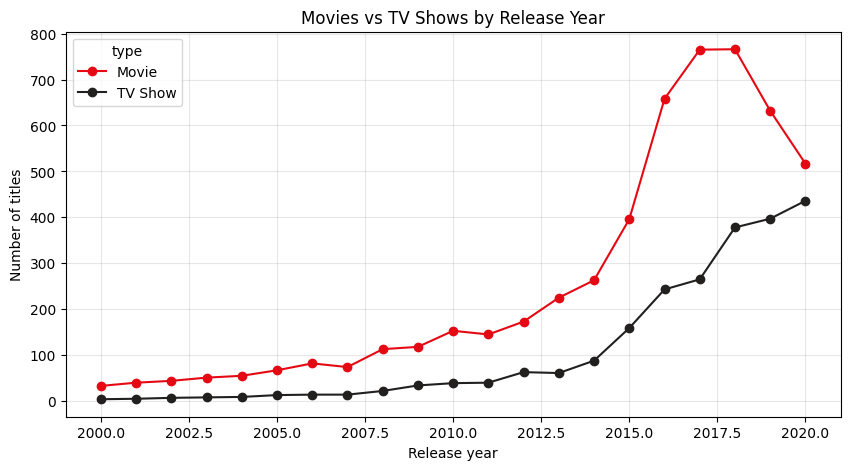

In [59]:
by_type.loc[2000:2020].plot(kind="line", marker="o", color=["#E50914", "#221F1F"], figsize=(10, 5))
plt.title("Movies vs TV Shows by Release Year")
plt.xlabel("Release year")
plt.ylabel("Number of titles")
plt.grid(alpha=0.3)
plt.savefig("release_by_type.png", dpi=150, bbox_inches="tight")
plt.show()

# Trend Analysis by Release Year: Key Findings

## Overview
- Titles analyzed: 8,786, released between 1925 and 2021 (74 different years)
- The dataset ends on 25 September 2021, so 2021 is a partial year
- Focus period for trends: 2000 to 2020 (2021 shown separately)

## Key Findings
1. **Content is mostly recent.** The 2010s account for 5,909 titles, about 67% of the whole catalog. Titles released before 2000 total only 525.
2. **Production grew fast through 2016.** Yearly titles rose from 351 in 2014 to 901 in 2016, with growth of +58.1% in 2015 and +62.3% in 2016.
3. **Growth then slowed.** It fell to +14.3% in 2017 and +11.1% in 2018, and the peak year was 2018 with 1,144 titles.
4. **A decline followed the peak.** Titles fell by 10.1% in 2019 and 7.4% in 2020, and 2020 ended 16.7% below the 2018 peak.
5. **Movies and TV Shows moved in opposite directions.** Movies dropped from 766 titles in 2018 to 517 in 2020 (about -32.5%), while TV Shows rose from 378 to 436 (about +15.3%).
6. **TV Shows are gaining share.** They made up about 33% of titles released in 2018 and about 46% in 2020.

## Business Interpretation
- Netflix's catalog is built mainly on recent content, which fits a strategy of keeping the library fresh.
- The slowdown after 2016 suggests the rapid expansion phase was ending.
- The shift from Movies to TV Shows suggests growing investment in series, which keep subscribers watching over time.

## Caveats
- **2021 is a partial year** (data ends in September 2021). Its drop (592 titles, -37.9%) is not a real decline, so it was excluded from the biggest-drop analysis.
- The data shows titles **in the Netflix catalog**, not everything produced worldwide. Titles removed or never licensed are missing.
- Recent years may be affected by the time titles take to appear in the catalog.
- Release year is when a title was made, not when it was added to Netflix.

## Charts and Files
- `release_trend.png`: line chart of titles per release year with a 3-year average and 2021 marked as partial
- `release_growth.png`: year-over-year growth bars
- `release_by_type.png`: Movies vs TV Shows over time


In [60]:
import os
print([f for f in os.listdir() if f.startswith("release")])


['release_by_type.png', 'release_growth.png', 'release_trend.png']
